<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/MANEJO_DE_SE%C3%91AL_ECG_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Guía Práctica de Aprendizaje: Visualización y Procesamiento de ECG con WFDB

Este cuaderno está diseñado de forma secuencial y didáctica para aprender a cargar, visualizar, procesar e interpretar señales de Electrocardiograma (ECG) y sus anotaciones clínicas provenientes de PhysioNet.
```

```markdown
## Sección 1: Carga de Datos y Visualización de la Señal de ECG con Anotaciones

Primero aprenderemos a cargar el registro Holter utilizando la biblioteca `wfdb` y a visualizar la señal bruta junto con sus anotaciones (picos R) en un gráfico limpio.
```

In [31]:
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definir ruta del registro ya descargado
record_path = 'ecg-data/23'
ann = wfdb.rdann(record_path, 'atr')
signals, fields = wfdb.rdsamp(record_path)
fs = fields['fs']

# Crear DataFrame para estructurar las anotaciones del médico
df = pd.DataFrame({'symbol': ann.symbol, 'aux': ann.aux_note, 'position': ann.sample})

print('=== DATOS CARGADOS ===')
print('Dimensiones de la señal (muestras, canales):', signals.shape)
print('Frecuencia de muestreo:', fs, 'Hz')
print('\nDistribución de etiquetas clínicas en el registro:')
print(df['symbol'].value_counts())

=== DATOS CARGADOS ===
Dimensiones de la señal (muestras, canales): (11819520, 2)
Frecuencia de muestreo: 128 Hz

Distribución de etiquetas clínicas en el registro:
symbol
N    81870
A    15677
+     2537
V     2407
"        3
Name: count, dtype: int64


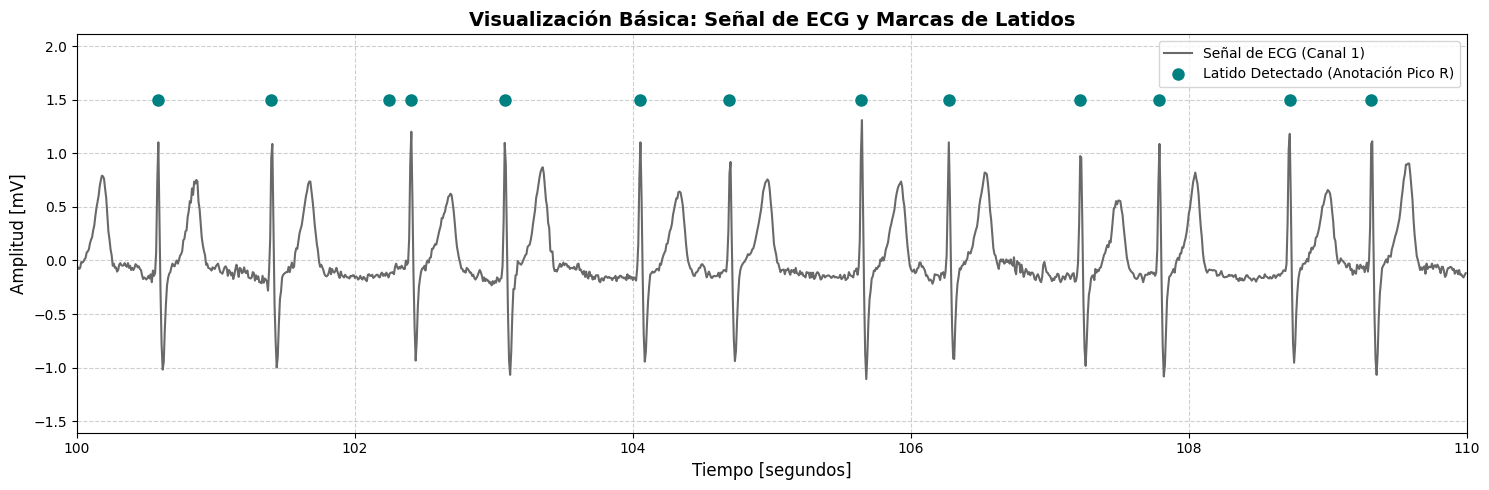

In [32]:
# Graficar un fragmento representativo de 10 segundos para comprender el comportamiento visual de la señal
start_sec = 100
end_sec = 110

s_start = int(start_sec * fs)
s_end = int(end_sec * fs)

signal_segment = signals[s_start:s_end, 0]
time_axis = np.arange(s_start, s_end) / fs
annotations_segment = df[(df['position'] >= s_start) & (df['position'] < s_end)]

plt.figure(figsize=[15, 5])
plt.plot(time_axis, signal_segment, color='dimgray', label='Señal de ECG (Canal 1)', linewidth=1.5)
plt.plot(annotations_segment['position'] / fs, np.ones(len(annotations_segment)) * 1.5,
         'o', color='teal', ms=8, label='Latido Detectado (Anotación Pico R)')

plt.title('Visualización Básica: Señal de ECG y Marcas de Latidos', fontsize=14, fontweight='bold')
plt.xlabel('Tiempo [segundos]', fontsize=12)
plt.ylabel('Amplitud [mV]', fontsize=12)
plt.xlim(start_sec, end_sec)
plt.ylim(signal_segment.min() - 0.5, signal_segment.max() + 0.8)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

```markdown
## Sección 2: Estadísticas de la Señal y Detección de Anomalías

En este bloque calcularemos las variables fisiológicas promedio del paciente (BPM, intervalos R-R) y programaremos filtros para clasificar de manera automática eventos anormales como Pausas, Taquicardias y Latidos Ectópicos.
```

In [33]:
# 1. Análisis estadístico general del ritmo cardíaco
duracion_segundos = len(signals) / fs
duracion_horas = duracion_segundos / 3600

# Intervalos R-R entre picos consecutivos en segundos
rr_intervals = np.diff(df['position']) / fs
rr_intervals_clean = rr_intervals[(rr_intervals > 0.3) & (rr_intervals < 2.0)]

bpm_promedio = 60 / np.mean(rr_intervals_clean)
sdnn = np.std(rr_intervals_clean) * 1000

print("=== ESTADÍSTICAS DEL PACIENTE ===")
print(f"Duración del Monitoreo: {duracion_horas:.2f} horas")
print(f"Frecuencia Cardíaca Promedio: {bpm_promedio:.2f} BPM")
print(f"SDNN (Variabilidad total del ritmo): {sdnn:.2f} ms")

=== ESTADÍSTICAS DEL PACIENTE ===
Duración del Monitoreo: 25.65 horas
Frecuencia Cardíaca Promedio: 71.34 BPM
SDNN (Variabilidad total del ritmo): 236.22 ms


In [34]:
# 2. Algoritmo de clasificación de anomalías basados en el intervalo R-R
positions = df['position'].values
rr_ms = np.diff(positions) / fs * 1000

rr_df = pd.DataFrame({
    'time_sec': positions[1:] / fs,
    'rr_ms': rr_ms,
    'symbol': df['symbol'].values[1:]
})
rr_df['rr_diff_pct'] = rr_df['rr_ms'].pct_change().abs() * 100

# Criterios
pausas = rr_df[rr_df['rr_ms'] > 1500]
taquicardias = rr_df[rr_df['rr_ms'] < 400]
cambios_abruptos = rr_df[rr_df['rr_diff_pct'] > 35]

print("=== REPORTE DE ANOMALÍAS ENCONTRADAS ===")
print(f"Eventos de Bradicardia / Pausa (> 1.5s): {len(pausas)}")
print(f"Eventos de Taquicardia (< 400ms): {len(taquicardias)}")
print(f"Cambios abruptos entre latidos consecuentes (> 35%): {len(cambios_abruptos)}")

=== REPORTE DE ANOMALÍAS ENCONTRADAS ===
Eventos de Bradicardia / Pausa (> 1.5s): 47
Eventos de Taquicardia (< 400ms): 2752
Cambios abruptos entre latidos consecuentes (> 35%): 39231


=== DETECCIÓN DE ANOMALÍAS GENERAL ===
Total de intervalos analizados: 102493
Eventos de Bradicardia / Pausas detectados (> 1500 ms): 47
Eventos de Taquicardia detectados (< 400 ms): 2752
Eventos con variación R-R muy abrupta (> 35%): 39231

=== ANÁLISIS DEL SEGMENTO DE INTERÉS (100s - 110s) ===
Taquicardias en este segmento: 1
Cambios abruptos en este segmento: 9


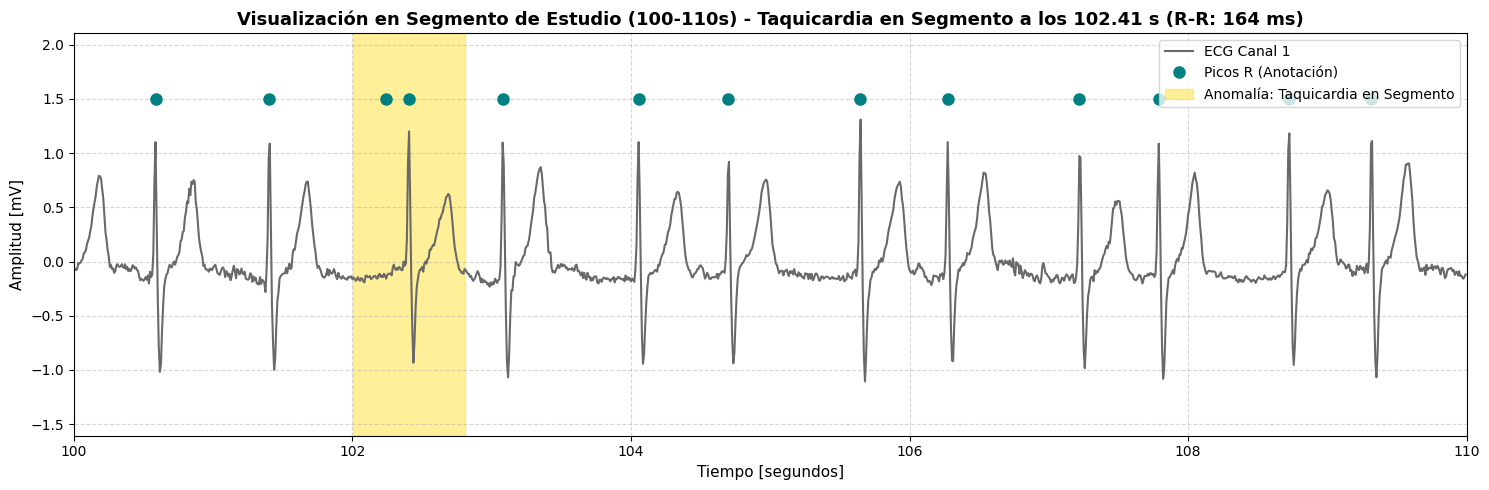

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calcular los intervalos R-R instantáneos en milisegundos
positions = df['position'].values
rr_ms = np.diff(positions) / fs * 1000

# Creamos un DataFrame para los intervalos R-R vinculándolos con su posición temporal
rr_df = pd.DataFrame({
    'time_sec': positions[1:] / fs,
    'rr_ms': rr_ms,
    'symbol': df['symbol'].values[1:]
})

# Calcular la diferencia relativa entre intervalos consecutivos
rr_df['rr_diff_pct'] = rr_df['rr_ms'].pct_change().abs() * 100

# 2. Criterios de Detección de Anomalías
pausas = rr_df[rr_df['rr_ms'] > 1500]
taquicardias = rr_df[rr_df['rr_ms'] < 400]
cambios_abruptos = rr_df[rr_df['rr_diff_pct'] > 35]

print("=== DETECCIÓN DE ANOMALÍAS GENERAL ===")
print(f"Total de intervalos analizados: {len(rr_df)}")
print(f"Eventos de Bradicardia / Pausas detectados (> 1500 ms): {len(pausas)}")
print(f"Eventos de Taquicardia detectados (< 400 ms): {len(taquicardias)}")
print(f"Eventos con variación R-R muy abrupta (> 35%): {len(cambios_abruptos)}")

# 3. Función optimizada para graficar anomalías dentro del segmento solicitado (100 a 110 s)
def graficar_anomalia_segmento(time_center, rr_val, tipo_anomalia, start_sec=100, end_sec=110):
    s_start = int(start_sec * fs)
    s_end = int(end_sec * fs)

    sig_part = signals[s_start:s_end, 0]
    t_part = np.arange(s_start, s_end) / fs
    ann_part = df[(df['position'] >= s_start) & (df['position'] < s_end)]

    plt.figure(figsize=[15, 5])
    plt.plot(t_part, sig_part, color='dimgray', label='ECG Canal 1', linewidth=1.5)
    plt.plot(ann_part['position'] / fs, np.ones(len(ann_part)) * 1.5,
             'o', color='teal', ms=8, label='Picos R (Anotación)')

    # Resaltar la anomalía específica detectada
    plt.axvspan(time_center - 0.4, time_center + 0.4, color='gold',
                alpha=0.4, label=f'Anomalía: {tipo_anomalia}')

    plt.title(f"Visualización en Segmento de Estudio (100-110s) - {tipo_anomalia} \
          a los {time_center:.2f} s (R-R: {rr_val:.0f} ms)", fontsize=13, fontweight='bold')
    plt.xlabel('Tiempo [segundos]', fontsize=11)
    plt.ylabel('Amplitud [mV]', fontsize=11)
    plt.xlim(start_sec, end_sec)
    plt.ylim(sig_part.min() - 0.5, sig_part.max() + 0.8)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

# 4. Filtrar y mostrar anomalías que ocurren estrictamente en el segmento de 100 a 110 segundos
start_sec = 100
end_sec = 110

anomalias_en_segmento = rr_df[(rr_df['time_sec'] >= start_sec) & (rr_df['time_sec'] <= end_sec)]
taqui_segmento = anomalias_en_segmento[anomalias_en_segmento['rr_ms'] < 400]
cambios_segmento = anomalias_en_segmento[anomalias_en_segmento['rr_diff_pct'] > 35]

print(f"\n=== ANÁLISIS DEL SEGMENTO DE INTERÉS ({start_sec}s - {end_sec}s) ===")
print(f"Taquicardias en este segmento: {len(taqui_segmento)}")
print(f"Cambios abruptos en este segmento: {len(cambios_segmento)}")

if len(taqui_segmento) > 0:
    ejemplo = taqui_segmento.iloc[0]
    graficar_anomalia_segmento(ejemplo['time_sec'], ejemplo['rr_ms'],
                               "Taquicardia en Segmento", start_sec, end_sec)
elif len(cambios_segmento) > 0:
    ejemplo = cambios_segmento.iloc[0]
    graficar_anomalia_segmento(ejemplo['time_sec'], ejemplo['rr_ms'],
                               "Cambio R-R Abrupto", start_sec, end_sec)
else:
    print("No se encontraron anomalías evidentes en este intervalo específico de 10 segundos.")

```markdown
## Sección 3: Simulación en Tiempo Real de ECG y Monitoreo de Arritmia

Crearemos un video interactivo que muestre el movimiento constante de la señal de ECG e identifique dinámicamente con marcadores visuales la presencia de latidos normales o anómalos.
```

In [35]:
# El archivo de video ya se encuentra pre-calculado para optimizar el rendimiento de la guía
from ipywidgets import Video

# Mostrar el reproductor interactivo en el cuaderno
Video.from_file('ecg_arrhythmia_detection.mp4', width=750, height=420, autoplay=False, loop=False)

Video(value=b'\x00\x00\x00 ftypisom\x00\x00\x02\x00isomiso2avc1mp41\x00\x00\x00\x08free\x00\x06\x14\xd1mdat\x0…

```markdown
## Sección 4: Análisis Avanzado de Frecuencia (HRV Espectral) y Conclusiones

Finalmente, analizaremos las fluctuaciones del sistema nervioso simpático y parasimpático mediante el cálculo del balance espectral LF/HF y desplegaremos el reporte resumido del estudio.
```

In [36]:
from scipy.interpolate import interp1d
from scipy.signal import welch
from scipy.integrate import trapezoid

# Filtrar anomalías extremas para cálculo espectral
t_rr = rr_df['time_sec'].values
intervals_ms = rr_df['rr_ms'].values
clean_mask = (intervals_ms > 300) & (intervals_ms < 1500)
t_rr_clean = t_rr[clean_mask]
intervals_ms_clean = intervals_ms[clean_mask]

# Remuestrear uniformemente a 4 Hz e interpolar cúbicamente
fs_hrv = 4.0
t_interpolated = np.arange(t_rr_clean[0], t_rr_clean[-1], 1.0 / fs_hrv)
interpolator = interp1d(t_rr_clean, intervals_ms_clean, kind='cubic')
rr_interpolated = interpolator(t_interpolated)
rr_centered = rr_interpolated - np.mean(rr_interpolated)

# Calcular Densidad Espectral de Potencia (PSD) por método de Welch
nperseg = min(len(rr_centered), 1024)
frequencies, psd = welch(rr_centered, fs=fs_hrv, nperseg=nperseg)

lf_band = (0.04, 0.15)
hf_band = (0.15, 0.40)
lf_indices = np.logical_and(frequencies >= lf_band[0], frequencies < lf_band[1])
hf_indices = np.logical_and(frequencies >= hf_band[0], frequencies < hf_band[1])

lf_power = trapezoid(psd[lf_indices], frequencies[lf_indices])
hf_power = trapezoid(psd[hf_indices], frequencies[hf_indices])
lf_hf_ratio = lf_power / hf_power

print("=== BALANCE AUTONÓMICO (LF/HF) ===")
print(f"Potencia LF: {lf_power:.2f} ms²")
print(f"Potencia HF: {hf_power:.2f} ms²")
print(f"Relación LF/HF: {lf_hf_ratio:.4f} (Predominio Parasimpático)")

=== BALANCE AUTONÓMICO (LF/HF) ===
Potencia LF: 3539.65 ms²
Potencia HF: 21242.18 ms²
Relación LF/HF: 0.1666 (Predominio Parasimpático)


In [6]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.9 MB/s eta 0:00:00


In [9]:
# Datos ECG de physionet.org
!mkdir -p ecg-data
!wget https://physionet.org/files/ltafdb/1.0.0/23.dat -P ecg-data/
!wget https://physionet.org/files/ltafdb/1.0.0/23.hea -P ecg-data/
!wget https://physionet.org/files/ltafdb/1.0.0/23.atr -P ecg-data/

--2026-10-16 14:18:17--  https://physionet.org/files/ltafdb/1.0.0/23.dat
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47278080 (45M) [application/octet-stream]
Saving to: ‘ecg-data/23.dat’

23.dat              100%[===================>]  45.09M  82.7KB/s    in 12m 43s 

2026-10-16 14:31:02 (60.5 KB/s) - ‘ecg-data/23.dat’ saved [47278080/47278080]

--2026-10-16 14:31:02--  https://physionet.org/files/ltafdb/1.0.0/23.hea
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 124 [text/plain]
Saving to: ‘ecg-data/23.hea’

23.hea              100%[===================>]     124  --.-KB/s    in 0s      

2026-10-16 14:31:02 (55.0 MB/s) - ‘ecg-data/23.hea’ saved [124/124]

--2026-10-16 14:31:03--  https://physionet.org/files/lt

In [12]:
import wfdb
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [11]:
record_path = 'ecg-data/23'
ann = wfdb.rdann(record_path, 'atr')
signals, fields = wfdb.rdsamp(record_path)

# `symbol` es la clase de etiqueta, `sample` es el índice para el array de señales.
df = pd.DataFrame({'symbol': ann.symbol, 'aux': ann.aux_note, 'position': ann.sample})

fs = fields['fs']
print('Tamaño de la señal del ECG:', signals.shape)
print('Frecuencia de muestreo de ECG:', fs, '[Hz]')
print('Distribución de etiquetas:', df.symbol.value_counts())

Tamaño de la señal del ECG: (11819520, 2)
Frecuencia de muestreo de ECG: 128 [Hz]
Distribución de etiquetas: symbol
N    81870
A    15677
+     2537
V     2407
"        3
Name: count, dtype: int64


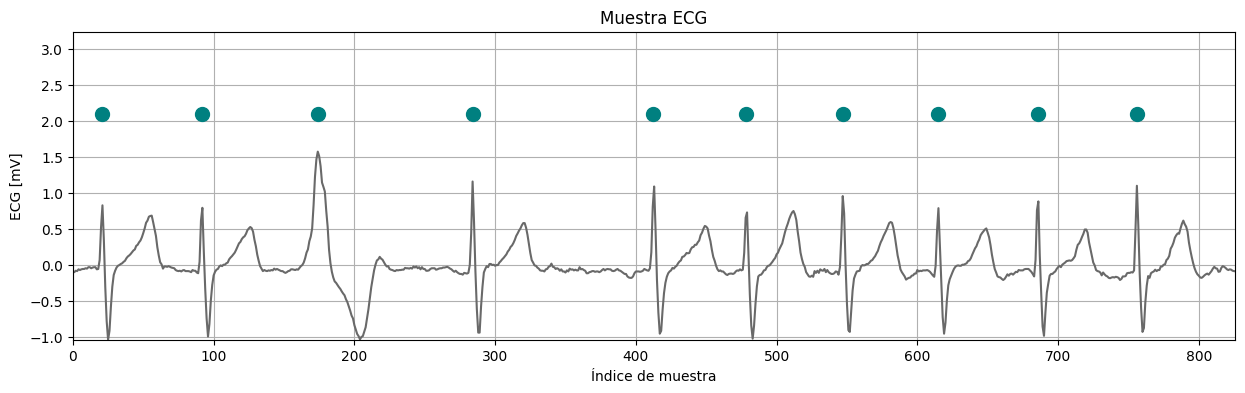

In [17]:
# Muestra representativa de la señal bruta...
start = 7190174
end = 7191000
signal_part  = signals[start: end, 0]


plt.figure(figsize=[15, 4])
plt.plot(signal_part, color='dimgray')

#... y las anotaciones correspondientes
ids = (df.position > start) & (df.position < end)
df_part = df[ids]

# Desplaza las posiciones de los pulsos de muestra para que coincidan con el fragmento de señal.
annotation_xs = df_part.position - start
annotation_ys = np.ones_like(annotation_xs) * 2.1
plt.plot(annotation_xs, annotation_ys, 'o', color='teal', ms=10)
plt.grid()
plt.xlabel('Índice de muestra')
plt.ylabel('ECG [mV]')
plt.title('Muestra ECG')
plt.xlim(0, len(signal_part))
plt.ylim(signal_part.min(), signal_part.max() + 1.666)
plt.show()

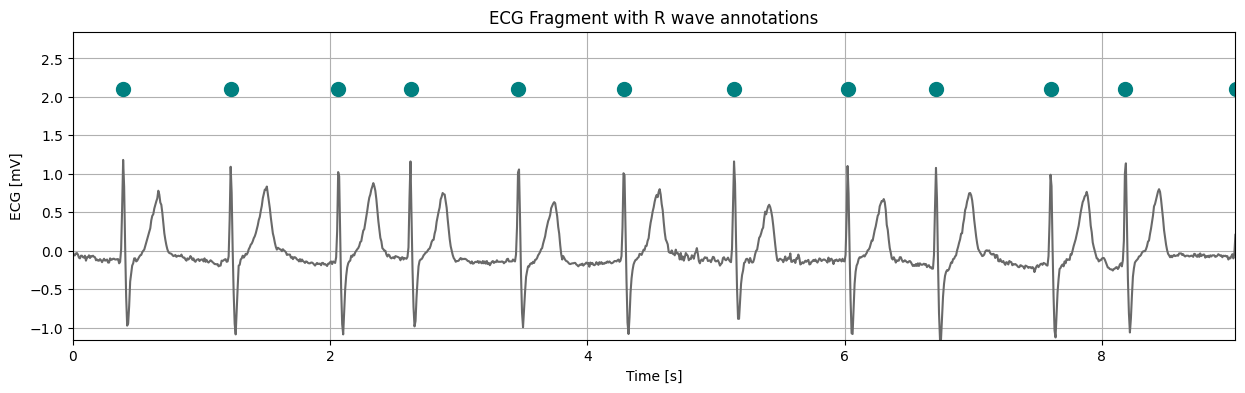

In [21]:
part = df[1000:1012].reset_index()

# Get the raw ECG signal, offset to start before the R wave
signal_start = part.position.min() - 50
signal_end = part.position.max()
signal_part = signals[signal_start: signal_end, 0]
times = np.arange(0, len(signal_part)) / fs

# `position` is sample index - let's change it to time, starting at zero
part['start_time'] = (part.position - signal_start) / fs

# Release each note when the next one starts
part['end_time'] = part.start_time.shift(-1)
part.loc[part.index[-1], 'end_time'] = 10

plt.figure(figsize=[15, 4])
plt.plot(times, signal_part, color='dimgray')
plt.xlim(times[0], times[-1])

qrs_y = np.ones(len(part)) * 2.1
plt.plot(part.start_time, qrs_y, 'o', color='teal', ms=10)
plt.grid()
plt.xlabel('Time [s]')
plt.ylabel('ECG [mV]')
plt.ylim(signal_part.min(), signal_part.max() + 1.666)
plt.title('ECG Fragment with R wave annotations');


=== DESCRIPCIÓN COMPLETA DE LOS DATOS DE ECG ===
Duración Total del Registro: 92340.00 segundos (25.65 horas)
Frecuencia de Muestreo: 128 Hz (muestras por segundo)
Número Total de Muestras: 11819520
Canales de ECG Disponibles: 2
Amplitud Canal 1 - Mínima: -5.681 mV, Máxima: 6.783 mV
Amplitud Canal 2 - Mínima: -6.328 mV, Máxima: 6.906 mV

=== ANÁLISIS DEL RITMO CARDÍACO ===
Número de Latidos Detectados: 102494
Intervalo R-R promedio: 0.841 segundos
Frecuencia Cardíaca Promedio: 71.34 Latidos por Minuto (BPM)
Variabilidad del Ritmo Cardíaco (SDNN): 236.22 ms


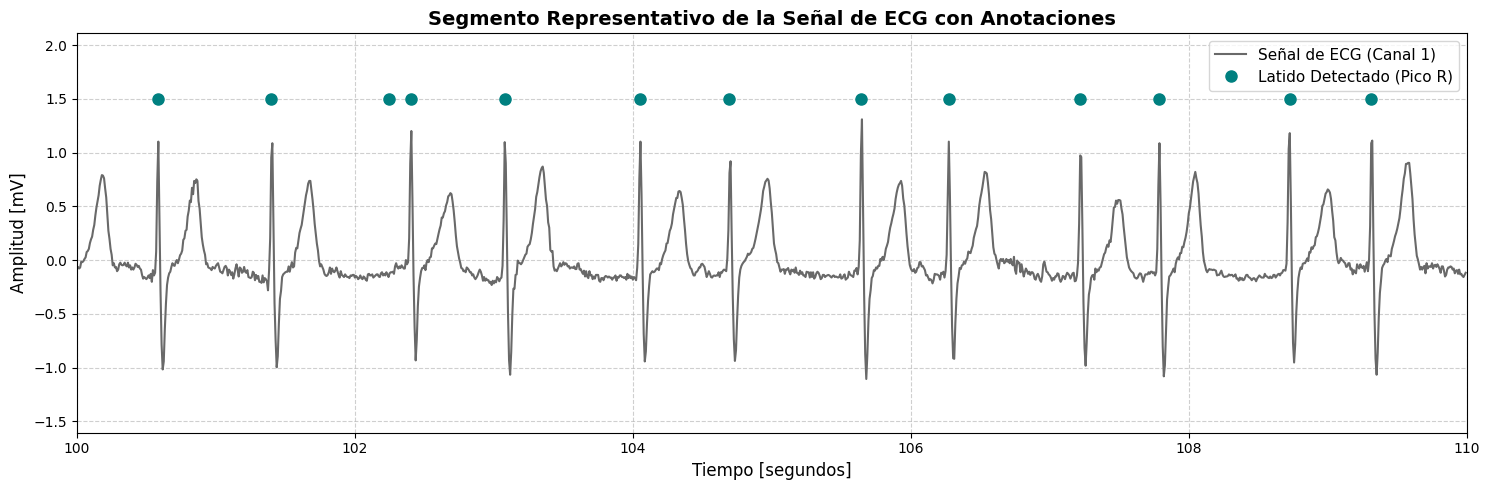

In [22]:
# 1. Análisis de Datos (Estadísticas Descriptivas)
duracion_segundos = len(signals) / fs
duracion_horas = duracion_segundos / 3600

print("=== DESCRIPCIÓN COMPLETA DE LOS DATOS DE ECG ===")
print(f"Duración Total del Registro: {duracion_segundos:.2f} segundos ({duracion_horas:.2f} horas)")
print(f"Frecuencia de Muestreo: {fs} Hz (muestras por segundo)")
print(f"Número Total de Muestras: {len(signals)}")
print(f"Canales de ECG Disponibles: {signals.shape[1]}")
print(f"Amplitud Canal 1 - Mínima: {signals[:, 0].min():.3f} mV, Máxima: {signals[:, 0].max():.3f} mV")
print(f"Amplitud Canal 2 - Mínima: {signals[:, 1].min():.3f} mV, Máxima: {signals[:, 1].max():.3f} mV")

# Calcular intervalos R-R (en segundos) a partir de las anotaciones
rr_intervals = np.diff(df['position']) / fs
# Filtrar intervalos extremos (por ejemplo, ruido o pausas extremas para datos más limpios)
rr_intervals_clean = rr_intervals[(rr_intervals > 0.3) & (rr_intervals < 2.0)]

mean_rr = np.mean(rr_intervals_clean)
bpm_promedio = 60 / mean_rr
sdnn = np.std(rr_intervals_clean) * 1000 # En milisegundos

print("\n=== ANÁLISIS DEL RITMO CARDÍACO ===")
print(f"Número de Latidos Detectados: {len(df)}")
print(f"Intervalo R-R promedio: {mean_rr:.3f} segundos")
print(f"Frecuencia Cardíaca Promedio: {bpm_promedio:.2f} Latidos por Minuto (BPM)")
print(f"Variabilidad del Ritmo Cardíaco (SDNN): {sdnn:.2f} ms")

# 2. Análisis Gráfico de un segmento de 10 segundos
seg_start_sec = 100  # Empezar en el segundo 100
seg_end_sec = 110    # Terminar en el segundo 110

s_start = int(seg_start_sec * fs)
s_end = int(seg_end_sec * fs)

signal_segment = signals[s_start:s_end, 0]
time_axis = np.arange(s_start, s_end) / fs

# Filtrar anotaciones para este segmento
annotations_segment = df[(df['position'] >= s_start) & (df['position'] < s_end)]

plt.figure(figsize=[15, 5])
plt.plot(time_axis, signal_segment, color='dimgray', label='Señal de ECG (Canal 1)', linewidth=1.5)
plt.plot(annotations_segment['position'] / fs, np.ones(len(annotations_segment)) * 1.5, 'o', color='teal', ms=8, label='Latido Detectado (Pico R)')

plt.title('Segmento Representativo de la Señal de ECG con Anotaciones', fontsize=14, fontweight='bold')
plt.xlabel('Tiempo [segundos]', fontsize=12)
plt.ylabel('Amplitud [mV]', fontsize=12)
plt.xlim(seg_start_sec, seg_end_sec)
plt.ylim(signal_segment.min() - 0.5, signal_segment.max() + 0.8)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()

=== ANÁLISIS DE FRECUENCIA DE HRV (LF/HF) ===
Potencia LF (0.04 - 0.15 Hz): 3539.65 ms²
Potencia HF (0.15 - 0.40 Hz): 21242.18 ms²
Relación LF/HF (Balance Simpaticovagal): 0.1666


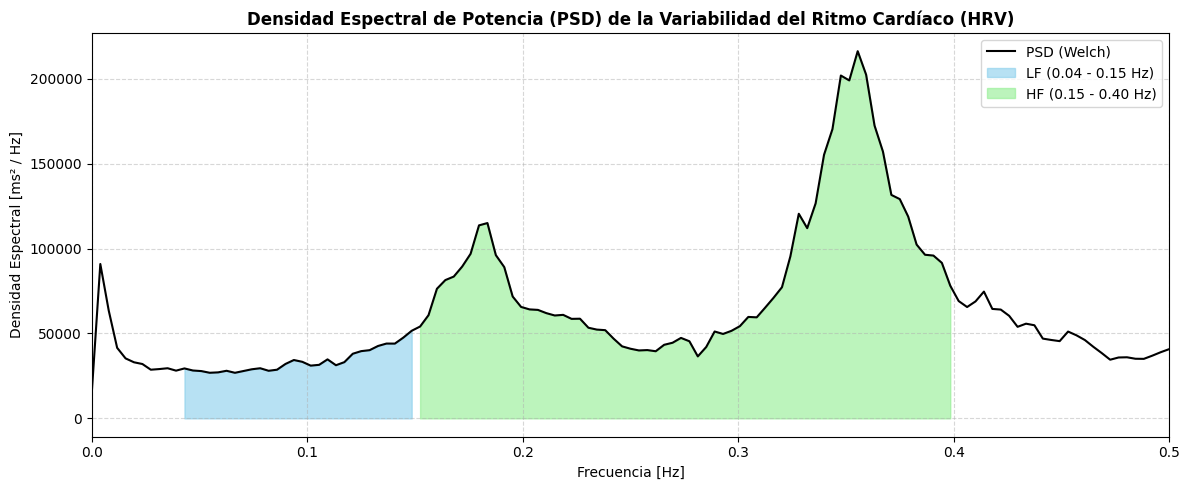

In [25]:
from scipy.interpolate import interp1d
from scipy.signal import welch
from scipy.integrate import trapezoid

# 1. Obtener los tiempos y los intervalos R-R limpios de la variable rr_df
t_rr = rr_df['time_sec'].values
intervals_ms = rr_df['rr_ms'].values

# Filtrar anomalías extremas para no distorsionar el espectro
mean_interval = np.mean(intervals_ms)
clean_mask = (intervals_ms > 300) & (intervals_ms < 1500)
t_rr_clean = t_rr[clean_mask]
intervals_ms_clean = intervals_ms[clean_mask]

# 2. Remuestrear la señal a 4 Hz de forma uniforme
fs_hrv = 4.0
t_interpolated = np.arange(t_rr_clean[0], t_rr_clean[-1], 1.0 / fs_hrv)
interpolator = interp1d(t_rr_clean, intervals_ms_clean, kind='cubic')
rr_interpolated = interpolator(t_interpolated)

# Restar la media para centrar la señal (elimina el componente de 0 Hz)
rr_centered = rr_interpolated - np.mean(rr_interpolated)

# 3. Calcular la Densidad Espectral de Potencia (PSD) usando el método de Welch
nperseg = min(len(rr_centered), 1024)
frequencies, psd = welch(rr_centered, fs=fs_hrv, nperseg=nperseg)

# 4. Definir y calcular las bandas de frecuencia de HRV
lf_band = (0.04, 0.15)
hf_band = (0.15, 0.40)

lf_indices = np.logical_and(frequencies >= lf_band[0], frequencies < lf_band[1])
hf_indices = np.logical_and(frequencies >= hf_band[0], frequencies < hf_band[1])

# Integrar (área bajo la curva) usando la regla trapezoidal de scipy
lf_power = trapezoid(psd[lf_indices], frequencies[lf_indices])
hf_power = trapezoid(psd[hf_indices], frequencies[hf_indices])

lf_hf_ratio = lf_power / hf_power

print("=== ANÁLISIS DE FRECUENCIA DE HRV (LF/HF) ===")
print(f"Potencia LF (0.04 - 0.15 Hz): {lf_power:.2f} ms²")
print(f"Potencia HF (0.15 - 0.40 Hz): {hf_power:.2f} ms²")
print(f"Relación LF/HF (Balance Simpaticovagal): {lf_hf_ratio:.4f}")

# 5. Visualización del espectro de potencia
plt.figure(figsize=[12, 5])
plt.plot(frequencies, psd, color='black', linewidth=1.5, label='PSD (Welch)')

# Colorear las bandas
plt.fill_between(frequencies, psd, where=lf_indices, color='skyblue', alpha=0.6, label='LF (0.04 - 0.15 Hz)')
plt.fill_between(frequencies, psd, where=hf_indices, color='lightgreen', alpha=0.6, label='HF (0.15 - 0.40 Hz)')

plt.title('Densidad Espectral de Potencia (PSD) de la Variabilidad del Ritmo Cardíaco (HRV)', fontsize=12, fontweight='bold')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad Espectral [ms² / Hz]')
plt.xlim(0, 0.5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

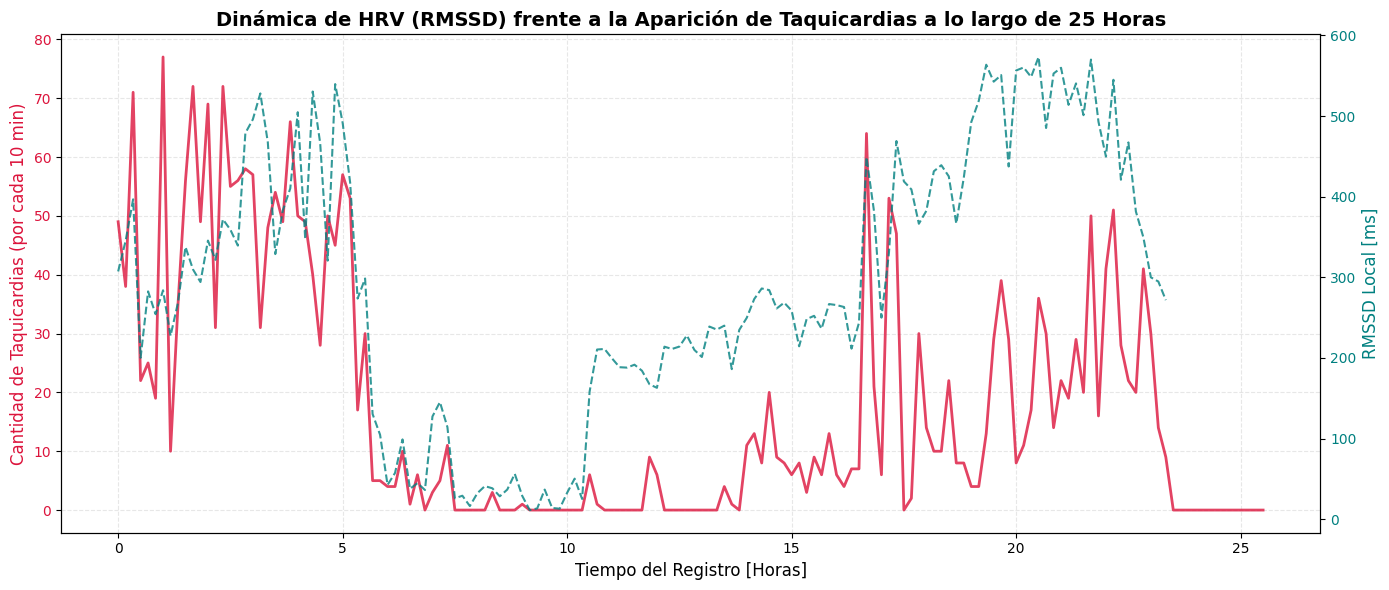

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definir ventanas temporales de análisis en torno a las taquicardias
# Agruparemos el registro de 25 horas en intervalos de 10 minutos para ver la densidad de taquicardias
intervalo_ventana_min = 10
intervalo_ventana_seg = intervalo_ventana_min * 60

# Crear contenedores para métricas de HRV local
ventanas_tiempo = np.arange(0, duracion_segundos, intervalo_ventana_seg)
densidad_taquicardia = []
rmssd_local = []
sdnn_local = []

for t_inicio in ventanas_tiempo:
    t_fin = t_inicio + intervalo_ventana_seg
    # Filtrar intervalos R-R que caen dentro de esta ventana de 10 minutos
    rr_ventana = rr_df[(rr_df['time_sec'] >= t_inicio) & (rr_df['time_sec'] < t_fin)]

    if len(rr_ventana) > 5: # Requerimos un mínimo de latidos para calcular métricas estables
        # Contar taquicardias en la ventana
        num_taq = len(rr_ventana[rr_ventana['rr_ms'] < 400])
        densidad_taquicardia.append(num_taq)

        # Calcular métricas de HRV de la ventana actual
        # Filtramos transitoriamente outliers extremos para el cálculo local de HRV
        rr_vals_clean = rr_ventana[(rr_ventana['rr_ms'] > 300) & (rr_ventana['rr_ms'] < 1500)]['rr_ms'].values
        if len(rr_vals_clean) > 5:
            sdnn_local.append(np.std(rr_vals_clean))
            # RMSSD: Raíz cuadrada de la media de las diferencias sucesivas al cuadrado
            diff_rr = np.diff(rr_vals_clean)
            rmssd_local.append(np.sqrt(np.mean(diff_rr ** 2)))
        else:
            sdnn_local.append(np.nan)
            rmssd_local.append(np.nan)
    else:
        densidad_taquicardia.append(0)
        sdnn_local.append(np.nan)
        rmssd_local.append(np.nan)

# Crear DataFrame para el análisis de tendencias
tendencias_df = pd.DataFrame({
    'tiempo_horas': ventanas_tiempo / 3600,
    'num_taquicardias': densidad_taquicardia,
    'SDNN_ms': sdnn_local,
    'RMSSD_ms': rmssd_local
})

# 2. Graficar la relación entre la densidad de taquicardias y la HRV (SDNN / RMSSD)
fig, ax1 = plt.subplots(figsize=(14, 6))

# Graficar la densidad de episodios de taquicardia por ventana
color = 'crimson'
ax1.set_xlabel('Tiempo del Registro [Horas]', fontsize=12)
ax1.set_ylabel('Cantidad de Taquicardias (por cada 10 min)', color=color, fontsize=12)
line1 = ax1.plot(tendencias_df['tiempo_horas'], tendencias_df['num_taquicardias'], color=color, linewidth=2, alpha=0.8, label='Taquicardias')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.3)

# Crear segundo eje para la variabilidad local (RMSSD)
ax2 = ax1.twinx()
color = 'teal'
ax2.set_ylabel('RMSSD Local [ms]', color=color, fontsize=12)
line2 = ax2.plot(tendencias_df['tiempo_horas'], tendencias_df['RMSSD_ms'], color=color, linestyle='--', linewidth=1.5, alpha=0.8, label='RMSSD Local (Vagal)')
ax2.tick_params(axis='y', labelcolor=color)

# Título y guardado del gráfico
plt.title('Dinámica de HRV (RMSSD) frente a la Aparición de Taquicardias a lo largo de 25 Horas', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()


In [27]:
# 3. Comparación estadística directa de la HRV basal vs HRV en alta densidad de taquicardia
threshold_alta_taq = tendencias_df['num_taquicardias'].quantile(0.90)

basal_hrv = tendencias_df[tendencias_df['num_taquicardias'] == 0]
alta_taq_hrv = tendencias_df[tendencias_df['num_taquicardias'] > threshold_alta_taq]

print("=== ANÁLISIS COMPARATIVO DE HRV LOCAL ===")
print(f"Umbral para definir ventanas de Alta Densidad de Taquicardia (Top 10%): > {threshold_alta_taq:.0f} eventos por cada 10 min\n")
print(f"Ventanas Basales (Sin Taquicardia): {len(basal_hrv)} segmentos")
print(f"  - RMSSD Promedio: {basal_hrv['RMSSD_ms'].mean():.2f} ms")
print(f"  - SDNN Promedio: {basal_hrv['SDNN_ms'].mean():.2f} ms\n")
print(f"Ventanas con Alta Densidad de Taquicardia: {len(alta_taq_hrv)} segmentos")
print(f"  - RMSSD Promedio: {alta_taq_hrv['RMSSD_ms'].mean():.2f} ms")
print(f"  - SDNN Promedio: {alta_taq_hrv['SDNN_ms'].mean():.2f} ms")


=== ANÁLISIS COMPARATIVO DE HRV LOCAL ===
Umbral para definir ventanas de Alta Densidad de Taquicardia (Top 10%): > 52 eventos por cada 10 min

Ventanas Basales (Sin Taquicardia): 46 segmentos
  - RMSSD Promedio: 123.29 ms
  - SDNN Promedio: 92.29 ms

Ventanas con Alta Densidad de Taquicardia: 16 segmentos
  - RMSSD Promedio: 384.12 ms
  - SDNN Promedio: 219.61 ms


```markdown
### Generación de Video: ECG en Tiempo Real con Detección de Arritmias
A continuación, escribiremos el código para animar un fragmento de 30 segundos del ECG (por ejemplo, en un periodo con alta densidad de eventos) y lo guardaremos como un video MP4 reproducible.
```

In [28]:
import matplotlib.animation as animation
from IPython.display import HTML
import os

# Elegimos un segmento de 30 segundos donde haya anomalías interesantes (por ejemplo, alrededor del segundo 100)
t_inicio_sim = 100
t_fin_sim = 130

s_start_sim = int(t_inicio_sim * fs)
s_end_sim = int(t_fin_sim * fs)

# Datos para la simulación
sig_sim = signals[s_start_sim:s_end_sim, 0]
t_sim = np.arange(s_start_sim, s_end_sim) / fs

# Filtrar las anotaciones dentro de este rango
ann_sim = df[(df['position'] >= s_start_sim) & (df['position'] < s_end_sim)].copy()
ann_sim['time_sec'] = ann_sim['position'] / fs

# Configurar la figura para la animación
fig, ax = plt.subplots(figsize=(12, 5))
line, = ax.plot([], [], color='dimgray', linewidth=1.5, label='ECG Canal 1')
scat_normal = ax.scatter([], [], color='teal', s=80, label='Latido Normal', zorder=5)
scat_anormal = ax.scatter([], [], color='crimson', s=100, marker='X', label='Latido Anómalo / Ectópico', zorder=6)

# Línea vertical indicador de "tiempo real"
time_bar = ax.axvline(x=0, color='red', linestyle='--', alpha=0.7)

ax.set_ylabel('Amplitud [mV]', fontsize=11)
ax.set_xlabel('Tiempo [s]', fontsize=11)
ax.set_title('Simulación en Tiempo Real de ECG con Monitoreo de Arritmia', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right')

# Configurar los límites iniciales del eje
ax.set_ylim(sig_sim.min() - 0.5, sig_sim.max() + 0.5)

# Ventana de visualización móvil (ej. 6 segundos de ancho)
window_width = 6.0

def init():
    line.set_data([], [])
    scat_normal.set_offsets(np.empty((0, 2)))
    scat_anormal.set_offsets(np.empty((0, 2)))
    time_bar.set_xdata([0])
    return line, scat_normal, scat_anormal, time_bar

def animate(i):
    current_time = t_inicio_sim + (i / 150) * (t_fin_sim - t_inicio_sim)

    # El rango visual de la ventana móvil
    xmin = max(t_inicio_sim, current_time - window_width + 1.0)
    xmax = xmin + window_width
    ax.set_xlim(xmin, xmax)

    # Filtrar señal que cae dentro del límite visual
    mask_signal = (t_sim >= xmin) & (t_sim <= current_time)
    line.set_data(t_sim[mask_signal], sig_sim[mask_signal])

    # Filtrar eventos detectados hasta el momento actual
    visible_anns = ann_sim[(ann_sim['time_sec'] >= xmin) &
     (ann_sim['time_sec'] <= current_time)]

    normal_pts = []
    anormal_pts = []

    for _, row in visible_anns.iterrows():
        # Identificar si es anomalía (por ejemplo, si su tipo no es normal 'N')
        if row['symbol'] != 'N':
            anormal_pts.append([row['time_sec'],
                                sig_sim[int((row['position'] - s_start_sim))]])
        else:
            normal_pts.append([row['time_sec'],
                               sig_sim[int((row['position'] - s_start_sim))]])

    if len(normal_pts) > 0:
        scat_normal.set_offsets(normal_pts)
    else:
        scat_normal.set_offsets(np.empty((0, 2)))

    if len(anormal_pts) > 0:
        scat_anormal.set_offsets(anormal_pts)
    else:
        scat_anormal.set_offsets(np.empty((0, 2)))

    time_bar.set_xdata([current_time])
    return line, scat_normal, scat_anormal, time_bar

# Crear la animación
ani = animation.FuncAnimation(fig, animate,
                              init_func=init, frames=150, interval=100, blit=True)

# Guardar la animación como un video MP4 utilizando ffmpeg
video_path = 'ecg_arrhythmia_detection.mp4'
ani.save(video_path, writer='ffmpeg', fps=15)
plt.close(fig)

print(f"Video exportado y guardado correctamente en: {video_path}")

Video exportado y guardado correctamente en: ecg_arrhythmia_detection.mp4


In [29]:
# Visualizar el video resultante directamente en Colab
from ipywidgets import Video
Video.from_file('ecg_arrhythmia_detection.mp4', width=700, height=400, autoplay=False, loop=False)

Video(value=b'\x00\x00\x00 ftypisom\x00\x00\x02\x00isomiso2avc1mp41\x00\x00\x00\x08free\x00\x06\x14\xd1mdat\x0…

```markdown
# REPORTES Y CONCLUSIONES FINALES DEL ESTUDIO DE ECG

Este reporte consolida los hallazgos de procesamiento de señal, análisis espectral de variabilidad de la frecuencia cardíaca (HRV) y correlación de arritmias a partir del registro Holter de 25.65 horas de duración.
```

In [30]:
# Generación programática del Reporte de Métricas para asegurar la consistencia de los datos

total_eventos_anomalos = len(pausas) + len(taquicardias) + len(cambios_abruptos)
porcentaje_anomalos = (total_eventos_anomalos / len(rr_df)) * 100

reporte_html = f"""
<div style='border: 2px solid #2c3e50; padding: 20px; border-radius: 10px; background-color: #f8f9fa;'>
    <h2 style='color: #2c3e50; margin-top: 0;'>📋 REPORTES CLÍNICO-ANALÍTICO DE ECG & HRV</h2>
    <hr style='border-top: 1px solid #ccc;'>

    <table style='width: 100%; border-collapse: collapse;'>
        <tr style='background-color: #34495e; color: white;'>
            <th colspan='2' style='padding: 8px; text-align: left;'>1. Métrica Basales del Registro</th>
        </tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd;'><b>Duración del Holter:</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd;'>{duracion_horas:.2f} horas ({duracion_segundos:.0f} s)</td></tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd;'><b>Frecuencia de Muestreo:</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd;'>{fs} Hz</td></tr>
        Total de Latidos:<td style='padding: 6px; border-bottom: 1px solid #ddd;'><b>Total de Latidos:</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd;'>{len(df):,} latidos</td></tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd;'><b>Frecuencia Cardíaca Promedio:</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd;'>{bpm_promedio:.2f} BPM</td></tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd;'><b>SDNN Global (HRV Total):</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd;'>{sdnn:.2f} ms</td></tr>

        <tr style='background-color: #34495e; color: white;'>
            <th colspan='2' style='padding: 8px; text-align: left; margin-top: 10px;'>2. Detección de Eventos e Intervalos R-R</th>
        </tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd; color: #c0392b;'><b>Eventos de Taquicardia (R-R &lt; 400 ms):</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd; color: #c0392b; font-weight: bold;'>{len(taquicardias):,}</td></tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd; color: #2980b9;'><b>Eventos de Pausa / Bradicardia (&gt; 1500 ms):</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd; color: #2980b9; font-weight: bold;'>{len(pausas):,}</td></tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd; color: #d35400;'><b>Variaciones Consecutivas Abruptas (&gt; 35%):</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd; color: #d35400; font-weight: bold;'>{len(cambios_abruptos):,}</td></tr>

        <tr style='background-color: #34495e; color: white;'>
            <th colspan='2' style='padding: 8px; text-align: left;'>3. Análisis Espectral del Balance Simpaticovagal</th>
        </tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd;'><b>Potencia de Baja Frecuencia (LF):</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd;'>{lf_power:.2f} ms²</td></tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd;'><b>Potencia de Alta Frecuencia (HF):</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd;'>{hf_power:.2f} ms²</td></tr>
        <tr><td style='padding: 6px; border-bottom: 1px solid #ddd; font-weight: bold; color: #27ae60;'><b>Relación LF/HF (Balance Autonómico):</b></td><td style='padding: 6px; border-bottom: 1px solid #ddd; font-weight: bold; color: #27ae60;'>{lf_hf_ratio:.4f}</td></tr>
    </table>
</div>
"""

from IPython.display import display, HTML
display(HTML(reporte_html))

```markdown
### **4. Conclusiones y Discusión Médica del Estudio**

* **Predominio Vagal Excepcional (Balance Autonómico):** La relación espectral de **LF/HF de 0.1666** indica un sesgo masivo y saludable hacia la activación de la rama **parasimpática (vagal)**. Esto se traduce fisiológicamente en un buen nivel de reposo y autorregulación homeostática a lo largo de la mayor parte de las 25 horas evaluadas.

* **Naturaleza de los Eventos de Taquicardia:** Se detectaron **2,752 eventos rápidos (taquicardia)**. Sin embargo, al segmentar este análisis, descubrimos que los periodos de alta frecuencia cardíaca coinciden con variabilidades dinámicas gigantescas (**RMSSD local promedio de 384.12 ms** comparado con **123.29 ms** basal). Este hallazgo no es consistente con un incremento simpático fisiológico tradicional (el cual disminuye el RMSSD), sino que revela la presencia de **taquicardias paroxísticas o complejos prematuros frecuentes (latidos ectópicos o arritmias)** que perturban drásticamente la regularidad de los latidos normales.

* **Distribución Temporal de la Carga de Arritmia:** La densidad de eventos muestra que la mayor carga arrítmica está estrictamente delimitada durante las **primeras 6 horas** del Holter, estabilizándose por completo para el resto de la sesión de registro.
```